BrM Nanostring Cosmx 6k (36 Samples, 3M cells)
=======================

In [ ]:
# ==============================================================================
# CosMx Brain Metastasis Spatial Transcriptomics
# ==============================================================================
# %pwd

# 加载相关工具包
from pathlib import Path
import pandas as pd
pd.set_option("display.max_columns", None)

import numpy as np
import os
import matplotlib.pyplot as plt
import palantir
import warnings
import gc
import pickle
import random
import torch

import networkx as nx
from sklearn.metrics.pairwise import cosine_similarity


import anndata as ad

from scipy.stats import gaussian_kde, entropy
from scipy.sparse import csr_matrix
import seaborn as sns

import sklearn
print(sklearn.__version__)  # 应输出 1.3.2

import scanpy as sc
import pyucell as uc

# pip install squidpy==1.3.1 scanpy==1.9.3 anndata==0.9.0 numpy==1.23.5 scipy==1.9.3 pandas==1.5.3 scikit-image==0.19.3 tifffile==2022.10.10 pillow==9.4.0 matplotlib==3.6.3 seaborn==0.12.2 numba==0.56.4 networkx==2.8.8 scikit-learn==1.2.2 statsmodels==0.13.5 omnipath==1.0.7   # 旧版 squidpy 才可以读入 
import squidpy as sq
print(sq.__version__)

import celltypist

# from napari_spatialdata import Interactive
import spatialdata as sd
import spatialdata_io

from scipy.spatial import distance_matrix
from collections import defaultdict

from statannotations.Annotator import Annotator
from itertools import combinations  # 自动生成所有两两配对

warnings.filterwarnings('ignore')
sc.logging.print_header()


1.9.0
1.8.1


/home/dingrong/miniconda3/envs/R453/lib/python3.14/site-packages/celltypist/classifier.py:11: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  from scanpy import __version__ as scv


Package,Version
pandas,2.3.3
numpy,2.4.3
matplotlib,3.10.9
palantir,1.4.4
torch,2.11.0 (2.10.0)
networkx,3.6.1
scikit-learn,1.9.0
anndata,0.12.16
scipy,1.17.1
seaborn,0.13.2


In [2]:

# 固定所有随机种子
seed = 1234
random.seed(seed)
np.random.seed(seed)
sc.settings.seed = seed


In [3]:
ad.settings.allow_write_nullable_strings = True  # 开启允许保存字符串类型

fig_dir = "/home/dingrong/Project/Brain_Metastasis_Cosmx/BM_Cosmx_Py/Result"
# fig_dir = Path().resolve() / "BM_Cosmx_Py"/"Result"
os.makedirs(fig_dir, exist_ok=True)

# ===================== PLOT SETTINGS =====================
sc.set_figure_params(
	facecolor="white", figsize=(6,6), dpi=300, fontsize=11, frameon=True
)
sc.settings.verbosity = 3
sc.settings.n_jobs = 16
sc.settings.figdir = fig_dir

plt.rcParams["savefig.dpi"] = 300
# plt.rcParams["save.bbox_inches"] = "tight"
plt.rcParams['axes.unicode_minus'] = False


# ===================== UTILITY FUNCTIONS =====================
def save_fig(name, fig_dir):
	plt.savefig(os.path.join(fig_dir, f"{name}.png"), dpi=300, bbox_inches="tight" )
	plt.savefig(os.path.join(fig_dir, f"{name}.pdf"), dpi=300, bbox_inches="tight" )
	# plt.close()

# 自动缩放空间坐标
def auto_scale_spatial(adata, target_scale=1000):
	"""
	自动将空间坐标缩放到 [0, target_scale] 范围
	"""
	x = adata.obsm["spatial"][:, 0]
	y = adata.obsm["spatial"][:, 1]
	# 缩放到 0~1
	x = (x - x.min()) / (x.max() - x.min())
	y = (y - y.min()) / (y.max() - y.min())
	# 放大到目标范围
	x = x * target_scale
	y = y * target_scale
	# 放回
	adata.obsm["spatial"] = np.column_stack([x, y])

def plot_umap_spatial(adata, color_key, fig_dir, suffix=""):
	sc.pl.umap(adata, color=color_key, show=False)   # , save=f"umap_{color_key}{suffix}"
	save_fig(f"umap.{color_key}{suffix}", fig_dir)
	for sid in sample_list:
		sub = adata[adata.obs["sample"] == sid].copy()
		if sub.n_obs < 50:
			continue
		# 修复空间坐标
		# sub.obsm["spatial"] = sub.obs[["CenterX_global_px", "CenterY_global_px"]].values  # 直接提取坐标画出来图是反的，CosMx 仪器：Y 轴向下增大（图像坐标系，左上角为原点）， Matplotlib/squidpy：Y 轴向上增大（数学坐标系，左下角为原点）
		# ✅ 永久翻转 Y 坐标
		x = sub.obs["CenterX_global_px"].values
		y = sub.obs["CenterY_global_px"].values
		y_flipped = y.max() + y.min() - y
		sub.obsm["spatial"] = np.column_stack([x, y_flipped])
		# 即使有 obsm["spatial"]，squidpy 依然会强制检查 adata.uns["spatial"], 强制添加 squidpy 必须要的空结构，解决 KeyError
		sub.uns["spatial"] = {"images": {}}
		# # 自动缩放你的 sub 数据坐标
		# auto_scale_spatial(sub, target_scale=1000)
		# sq.pl.spatial_scatter(sub, color=color_key, size=1, img=False, frameon=False, shape=None)  # , library_key="fov" , palette="tab20" , save=f"spatial.{color_key}.{sid}.{suffix}" # img=False, NanoString CosMx 数据，没有组织病理学图像（H&E）
		sq.pl.spatial_scatter(sub, color=color_key, size=1, img=False, frameon=False, legend_fontsize=4, shape=None)  # , library_key="fov" , save=f"spatial.{color_key}.{sid}.{suffix}"  , squidpy 中 legend_loc 只能填：right / left / top / bottom / center ,  scanpy 支持 legend_loc='outside right'
		# ax.invert_yaxis()  # ✅ 临时翻转 Y 轴，匹配 CosMx 原始图像
		save_fig(f"spatial_{color_key}.{sid}{suffix}", fig_dir)

def plot_enrich_bar(df, x_col, y_col, title, name, fig_dir, topn=15):
	plt.figure(figsize=(10,6))
	df_top = df.head(topn).sort_values(x_col, ascending=True)
	sns.barplot(data=df_top, x=x_col, y=y_col)
	plt.title(title, fontsize=12)
	plt.tight_layout()
	save_fig(name, fig_dir)

def plot_boxplot(df, cols, name, fig_dir, title=""):
	plt.figure(figsize=(10,6))
	ax = df[cols].boxplot(grid=False)
	ax.grid(False)  # 去掉网格线
	plt.title(title)
	plt.tight_layout()
	save_fig(name, fig_dir)

样本信息
---------------------------------------------

In [ ]:
# ===================== GLOBAL CONFIG =====================
project_name = "BM_Cosmx_Py"
out_dir = "/home/dingrong/Project/Brain_Metastasis_Cosmx/BM_Cosmx_Py/Result/"
# out_dir = "/home/dingrong/Project/Brain_Metastasis_Cosmx/BM_Cosmx_Py/Result.bk/"
fig_dir = os.path.join(out_dir, "figures")
csv_dir = os.path.join(out_dir, "tables")
os.makedirs(out_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)
os.makedirs(csv_dir, exist_ok=True)

In [ ]:

adata = sc.read_h5ad(os.path.join(out_dir, f"{project_name}.h5ad"))
adata


【Step 9】 Cell Type Annotation from Seurat
---------------------------------------------

In [ ]:

# ==============================================================================
# METHODS: 9. Cell Type Annotation from Seurat
# ==============================================================================
print("\n【Step 9】 Cell Type Annotation")
fig_dir = os.path.join(out_dir, "Step09_Annotation")
csv_dir = os.path.join(out_dir, "Step09_Annotation")
os.makedirs(fig_dir, exist_ok=True)
os.makedirs(csv_dir, exist_ok=True)



【Step 9】 Cell Type Annotation


In [ ]:

# 固定所有随机种子
seed = 1234
random.seed(seed)
np.random.seed(seed)
sc.settings.seed = seed


In [ ]:
CellType_colors = {
	"Astrocyte_PTPRZ1": "#33A02C",
	"Astrocyte_SLC1A2": "#BE9C2E",
	"Astrocyte_TNC": "#FFFF00",
	"Bcell": "#F7D42A",
	"Doublet": "#A8A6A7",
	"Endo_Stroma": "#6E8E84",
	"Endothelial": "#FF7F0E",
	"Fibroblast_COL7A1": "#AA9486",
	"Fibroblast_LUM": "#A6761D",
	"Macrophage_C1Q": "#AD8CFF",
	"Macrophage_CD163": "#86486F",
	"Macrophage_SPP1": "#6B42C8",
	"MCC_c0": "#FA41CA",
	"MCC_c1_EMT": "#FF7F00",
	"MCC_c10_Cycle_S": "#015E05",
	"MCC_c11_IFN": "#FCF40E",
	"MCC_c14_Cilium": "#8B5B45",
	"MCC_c2_Immune": "#007ED3",
	"MCC_c3": "#E50000",
	"MCC_c4_Hypoxic": "#894FC6",
	"MCC_c5_Cycle_G2M": "#7FD2FF",
	"MCC_c6_Cycle_S": "#00C19B",
	"MCC_c7_Mito": "#FEC3BB",
	"MCC_c9_Stress": "#49F149",
	"Microglial": "#68D359",
	"Monocyte": "#377EB8",
	"Mural": "#FFA88B",
	"Myeloid_Cycle": "#FF6AD5",
	"Neuron_Excitatory_LAMP5": "#FF00FF",
	"Neuron_Excitatory_RELN": "#FB832D",
	"Neuron_Excitatory_SYT1": "#C72E29",
	"Neuron_Inhibitory_CALB1": "#016392",
	"Neuron_Inhibitory_PVALB": "#8085E9",
	"Oligodendrocyte_CNP": "#0080FF",
	"Oligodendrocyte_MBP": "#EEAAEE",
	"Oligodendrocyte_NGFR": "#1ABC9C",
	"Oligodendrocyte_PLP1": "#47ECDD",
	"Oligodendrocyte_PRUNE2": "#9B59B6",
	"Tcell": "#30ACEC",
	"Undefined": "#B0B0B0"
}
categories = adata.obs["CellType"].cat.categories  # 拿到所有细胞类型顺序
color_list = [CellType_colors[ct] for ct in categories]  # 按顺序生成颜色
adata.uns["CellType_colors"] = color_list  

fig, ax = plt.subplots(figsize=(7, 3))
sc.pl.umap(adata, color="CellType", show=False, s=1, alpha=1, frameon=True, ax=ax)  # , legend_loc="on data" , save="umap_celltype"
ax.set_aspect("equal") # 强制xy等比例，UMAP坐标轴1:1
save_fig("umap_CellType_anno.adata", fig_dir)

# fig, ax = plt.subplots(figsize=(7, 3))
# sc.pl.umap(adata, color="sample", show=False, s=1, alpha=1, frameon=True, ax=ax)  # , legend_loc="on data" , save="umap_celltype"
# ax.set_aspect("equal") # 强制xy等比例，UMAP坐标轴1:1
# save_fig("umap_sample_anno.adata", fig_dir)


In [ ]:
# adata.obs["CellType_main"] = adata.obs["CellType_main"].astype("category")
CellType_main_colors = {
	"MCC": "#E31A1C",
	"Neuron": "#18BC9C",
	"Glial": "#CCDE8B",
	"Bcell": "#F7D42A",
	"Tcell": "#30ACEC",
	"Myeloid": "#6B42C8",
	"Stroma": "#A6761D"
}
categories = adata.obs["CellType_main"].cat.categories  # 拿到所有细胞类型顺序
color_list = [CellType_main_colors[ct] for ct in categories]  # 按顺序生成颜色
adata.uns["CellType_main_colors"] = color_list  

fig, ax = plt.subplots(figsize=(4, 3))
sc.pl.umap(adata, color="CellType_main", show=False, s=1, alpha=1, frameon=True, ax=ax)  # , legend_loc="on data" , save="umap_celltype"
ax.set_aspect("equal") # 强制xy等比例，UMAP坐标轴1:1
save_fig("umap_CellType_main_anno.adata", fig_dir)


【Step 9.2】 Cell Markers
---------------------------------------------

In [ ]:
# ==============================================================================
# METHODS: 9.2 Cell Markers check
# ==============================================================================
print("\n【Step 9.2】 Cell Markers")
fig_dir = os.path.join(out_dir, "Step09_2_Markers")
csv_dir = os.path.join(out_dir, "Step09_2_Markers")
os.makedirs(fig_dir, exist_ok=True)
os.makedirs(csv_dir, exist_ok=True)



【Step 9.2】 Cell Markers


In [ ]:

# 固定所有随机种子
seed = 1234
random.seed(seed)
np.random.seed(seed)
sc.settings.seed = seed


In [ ]:
marker_dict = {
	"Markers": ["EPCAM", "KRT7", "KRT8", "KRT19", "CXCL17", "CCNL2", "VEGFA", "JUN", "IFI44L", "TPPP3", "AGR3", "ENO2", "SNAP25", "SYT1", "RELN", "LAMP5", "GAD1", "PVALB", "CALB1", "GFAP", "CLU", "PTPRZ1", "SLC1A2", "TNC", "S100B", "MOG", "PLP1", "MBP", "CNP", "CLDN11", "NGFR", "PRUNE2", "CD79A", "IGKC", "IGHA1", "CD3D", "TRAC", "GZMA", "CD163", "CD68", "C1QA", "SPP1", "CD83", "LYZ", "COL1A1", "LUM", "COL7A1", "ACTA2", "PECAM1", "FLT1", "CLDN5", "MKI67", "CDK1", "TOP2A"]
}

for cell_name, marker_list in marker_dict.items():
	print(f"正在绘制：{cell_name}")
	valid_markers  = [g for g in marker_list if g in adata.var_names]
	print(valid_markers )

	if len(valid_markers)==0:
		print(f"{cell_name} 无有效基因，跳过")
		continue
	
	sc.pl.dotplot(adata, var_names=valid_markers , groupby="CellType", standard_scale="var", show=False)  # , save="marker_dotplot"
	save_fig(f"CellType_marker_dotplot.{cell_name}", fig_dir)

	sc.pl.stacked_violin(adata, valid_markers, groupby="CellType", swap_axes=False, dendrogram=True, show=False) # valid_markers [:6]
	# sc.pl.violin(adata, valid_markers , groupby="CellType", show=False) # valid_markers [:6]
	save_fig(f"CellType_marker_violin.{cell_name}", fig_dir)
	plt.close()


正在绘制：Markers
['EPCAM', 'KRT7', 'KRT8', 'KRT19', 'CXCL17', 'VEGFA', 'JUN', 'IFI44L', 'ENO2', 'SNAP25', 'SYT1', 'RELN', 'GAD1', 'PVALB', 'CALB1', 'GFAP', 'CLU', 'PTPRZ1', 'SLC1A2', 'TNC', 'S100B', 'MOG', 'PLP1', 'MBP', 'CNP', 'NGFR', 'CD79A', 'IGKC', 'IGHA1', 'CD3D', 'TRAC', 'GZMA', 'CD163', 'CD68', 'C1QA', 'SPP1', 'CD83', 'LYZ', 'COL1A1', 'LUM', 'COL7A1', 'ACTA2', 'PECAM1', 'FLT1', 'CLDN5', 'MKI67', 'CDK1', 'TOP2A']


【Step 10.1】 Cell/Sample Composition Statistics
---------------------------------------------

In [14]:

# ==============================================================================
# METHODS: 10. Cell/Sample Composition Statistics
# Detailed Description: 
# ==============================================================================
print("\n【Step 10.1】 CellType")
fig_dir = os.path.join(out_dir, "Step10_Composition", "Composition_Statistics")
csv_dir = os.path.join(out_dir, "Step10_Composition", "Composition_Statistics")
os.makedirs(fig_dir, exist_ok=True)
os.makedirs(csv_dir, exist_ok=True)



【Step 10.1】 CellType


In [15]:

# 固定所有随机种子
seed = 1234
random.seed(seed)
np.random.seed(seed)
sc.settings.seed = seed


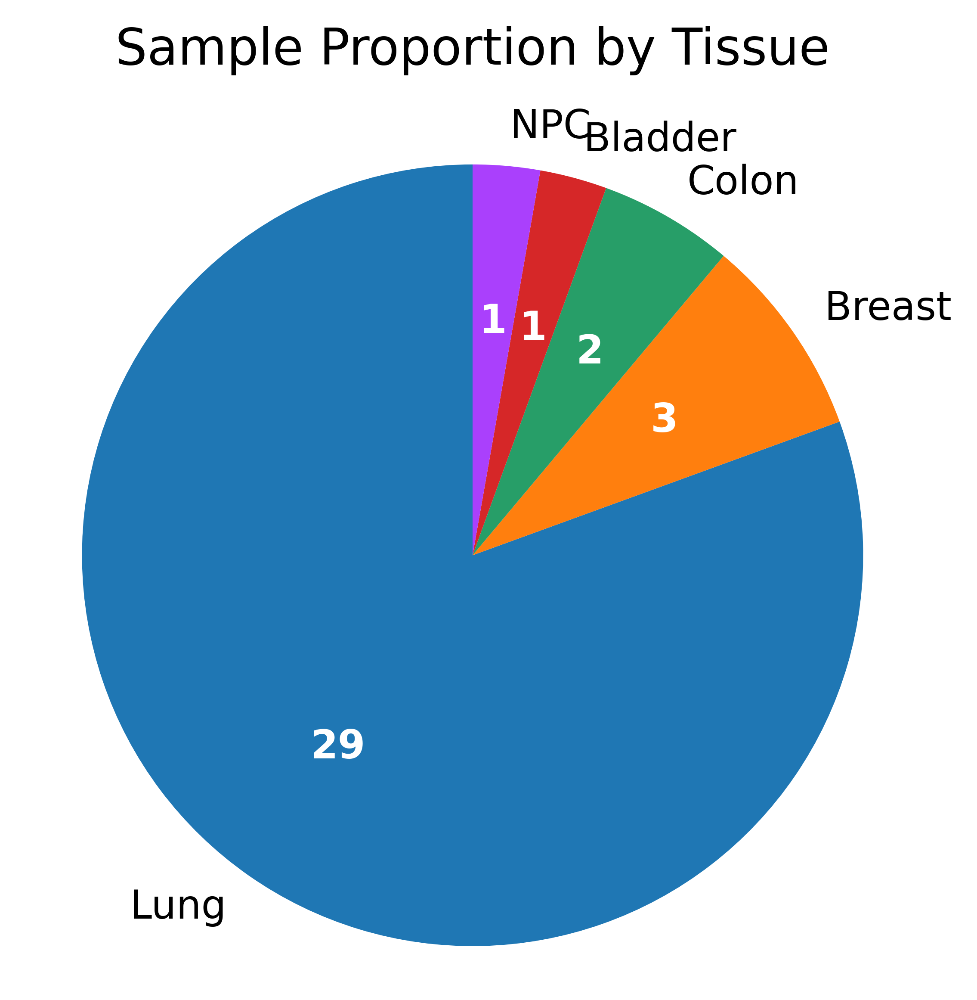

In [16]:
# 提取每个样本唯一对应的Tissue
df_meta = adata.obs[["sample", "Tissue"]].drop_duplicates(subset="sample")
tissue_count = df_meta["Tissue"].value_counts()

# 绘图
plt.figure(figsize=(4, 4))
wedges, texts, autotexts = plt.pie(
	tissue_count.values,
	labels=tissue_count.index,
	autopct=lambda pct: f"{int(pct/100 * sum(tissue_count.values))}",
	# autopct=lambda pct: f"{pct:.1f}%\n(n={int(pct/100 * sum(tissue_count.values))})",
	startangle=90,
	textprops={"fontsize": 11}
)
# 美化文字
for autotext in autotexts:
	autotext.set_color("white")
	autotext.set_fontweight("bold")
plt.title("Sample Proportion by Tissue", fontsize=14, pad=20)
plt.axis("equal")
plt.tight_layout()
save_fig("Sample_Tissue_PieChart", fig_dir)

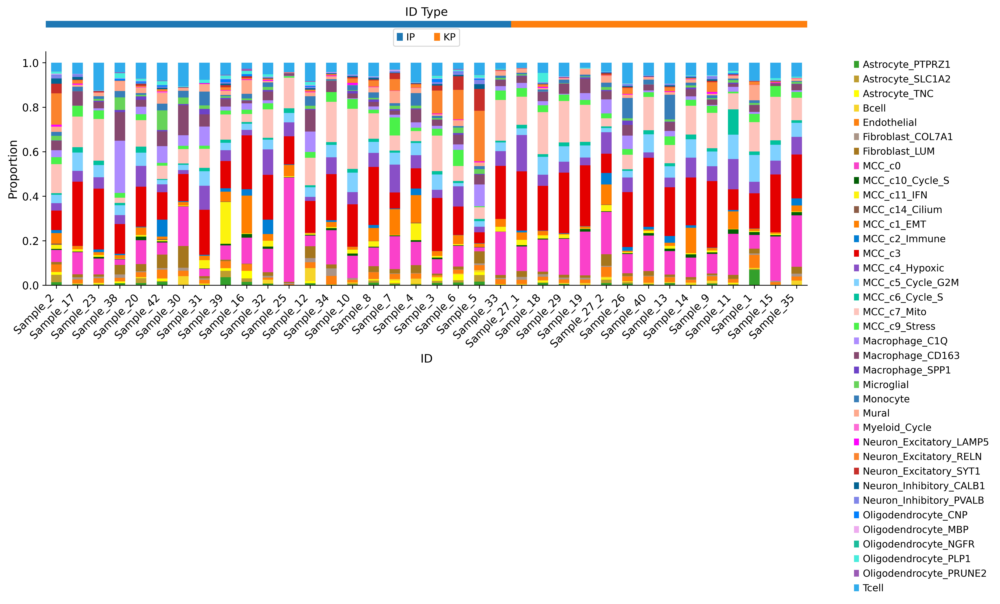

: 

In [ ]:
# 【公共部分：样本按 Type 排序】
df_obs = adata.obs.copy()
ID_type = df_obs[["ID", "Type"]].drop_duplicates().set_index("ID")
ID_order = ID_type.sort_values("Type").index.tolist()
type_labels_sorted = ID_type.loc[ID_order]["Type"].values
unique_types = np.unique(type_labels_sorted)
# Type 配色
type_palette = sns.color_palette("tab10", len(unique_types))
type_color_map = dict(zip(unique_types, type_palette))

# ==============================
# 6. 每个 ID 的 CellType 比例（堆叠柱状图 + 顶部Type颜色条）
# ==============================
fig, (ax_top, ax_main) = plt.subplots(2, 1, figsize=(14, 5), gridspec_kw={'height_ratios': [0.3, 10]})
# 比例数据 + 排序
ct_ID = pd.crosstab(df_obs['ID'], df_obs['CellType']).loc[ID_order]
ct_ID_prop = ct_ID.div(ct_ID.sum(axis=1), axis=0)
# 顶部 Type 颜色条
for i, t in enumerate(type_labels_sorted):
    ax_top.bar(i, 1, color=type_color_map[t], width=1)
ax_top.set_xlim(-0.5, len(ID_order)-0.5)
ax_top.axis("off")
ax_top.set_title("ID Type", fontsize=12, pad=5)
# Type 图例
handles_type = [plt.Rectangle((0,0),1,1, color=type_color_map[t]) for t in unique_types]
ax_top.legend(handles_type, unique_types, loc="upper center", bbox_to_anchor=(0.5, 0.5), ncol=6)
# 主图：堆叠柱状图
cell_types = df_obs["CellType"].cat.categories
color_map = dict(zip(cell_types, adata.uns["CellType_colors"]))
colors = [color_map[ct] for ct in ct_ID_prop.columns]
ct_ID_prop.plot(kind='bar', stacked=True, color=colors, ax=ax_main)
ax_main.grid(False)
ax_main.legend(bbox_to_anchor=(1.05, 1), loc="upper left", frameon=False, fontsize=10)
# ax_main.set_title('CellType per ID', fontsize=14, pad=15)
ax_main.set_ylabel('Proportion', fontsize=12)
ax_main.set_xlabel('ID', fontsize=12)
ax_main.set_xticklabels(ax_main.get_xticklabels(), rotation=45, ha='right')
plt.tight_layout()
save_fig('ID_CellType_proportion_stack', fig_dir)


In [ ]:

div_df = []
for sid in sample_list:
	sub = adata[adata.obs["sample"]==sid]
	type = sub.obs["Type"].unique()[0]
	tissue = sub.obs["Tissue"].unique()[0]
	location = sub.obs["Location"].unique()[0]
	ct_counts = sub.obs["CellType"].value_counts()
	shannon = -sum( (ct_counts/ct_counts.sum()) * np.log(ct_counts/ct_counts.sum()) )
	simpson = 1 - sum( (ct_counts**2) / (ct_counts.sum()**2) )
	div_df.append([sid, type, tissue, location, sub.n_obs, shannon, simpson])
div_df = pd.DataFrame(div_df, columns=["sample", "Type", "Tissue", "Location", "cell_count", "shannon_diversity", "simpson_index"])
div_df.to_csv(os.path.join(csv_dir, "sample_heterogeneity_index.csv"), index=False)
div_df.head()

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

IP vs. KP: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:2.033e-02 U_stat=2.260e+02
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

IP vs. KP: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:4.597e-02 U_stat=2.160e+02
✅ Sample heterogeneity quantification completed
   ├─ Mean Shannon diversity: 2.626
   ├─ Mean Simpson index: 0.888
   ├─ Most diverse sample: X15S8793_2
   └─ Least diverse sample: X23s30119


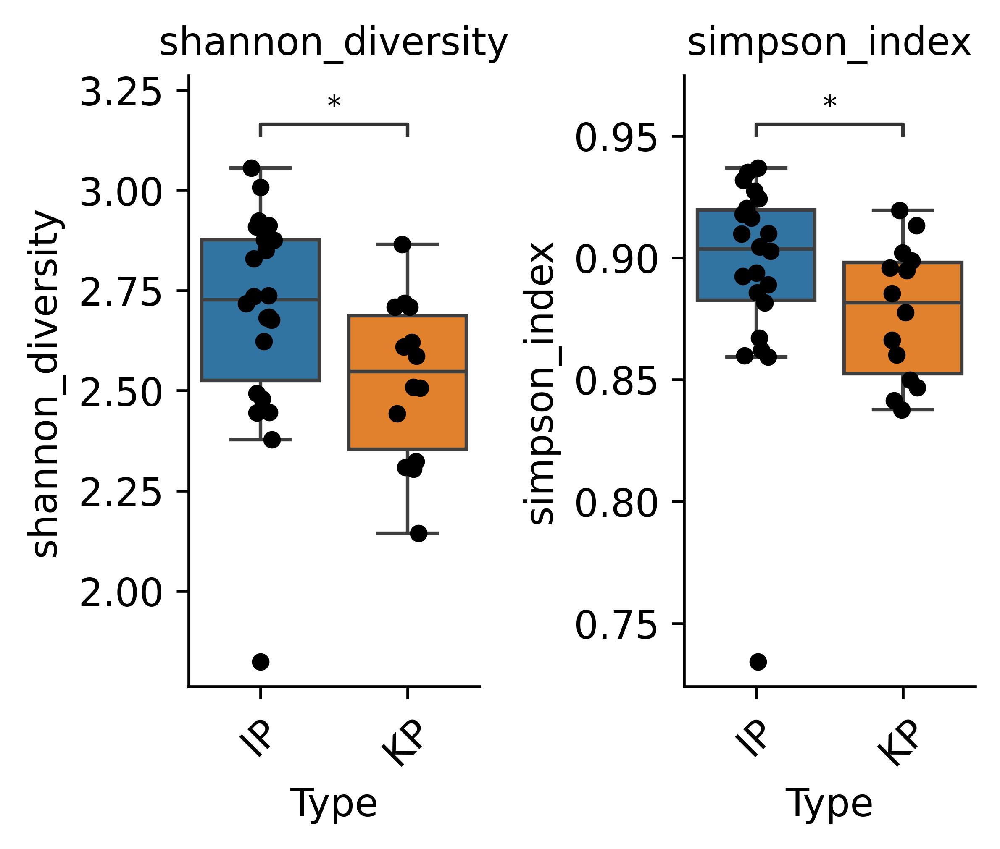

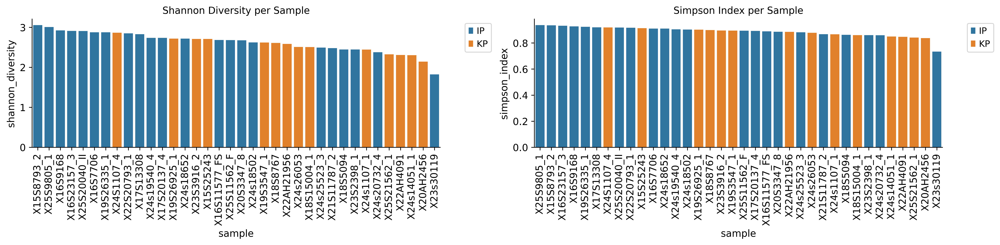

In [41]:
import seaborn as sns
import matplotlib.pyplot as plt
from itertools import combinations
from statannotations.Annotator import Annotator


# 标准Type分组箱线图 + 显著性（推荐！）
fig, axes = plt.subplots(1, 2, figsize=(4, 3.5))
for ax, metric in zip(axes, ["shannon_diversity", "simpson_index"]):
	palette = sns.color_palette("tab10", len(type_list))  # 自动配色
	sns.boxplot(data=div_df, x="Type", y=metric, palette=palette, dodge=False, fliersize=0, ax=ax)  # 
	sns.stripplot(data=div_df, x="Type", y=metric, color="black", s=5, ax=ax)
	# 两两显著性
	type_list = div_df["Type"].unique()
	all_pairs = list(combinations(type_list, 2))
	annotator = Annotator(ax, pairs=all_pairs, data=div_df, x="Type", y=metric)
	annotator.configure(test="Mann-Whitney", comparisons_correction="bonferroni", text_format="star", loc="inside", line_width=1, fontsize=8) #   # 独立 t 检验：t-test_ind, Welch t 检验（推荐）：t-test_welch, 非参数（两组）：Mann-Whitney, 配对：Wilcoxon, 多组：Kruskal
	annotator.apply_and_annotate()
	ax.grid(False)
	ax.tick_params(axis='x', rotation=45)
	ax.set_title(metric)
plt.tight_layout()
save_fig("sample_heterogeneity_boxplot_Type", fig_dir)


plt.figure(figsize=(16,4))
plt.subplot(1,2,1)
# 按 shannon_diversity 降序排序
order_shannon = div_df.sort_values("shannon_diversity", ascending=False)["sample"].values
sns.barplot(data=div_df, x="sample", y="shannon_diversity", hue='Type', order=order_shannon)   # , color="#9b59b6"
plt.grid(False)
plt.xticks(rotation=90)
plt.legend(bbox_to_anchor=(1.05,1), loc="upper left")
plt.title("Shannon Diversity per Sample")
plt.subplot(1,2,2)
# 按 simpson_index 降序排序
order_simpson = div_df.sort_values("simpson_index", ascending=False)["sample"].values
sns.barplot(data=div_df, x="sample", y="simpson_index", hue='Type', order=order_simpson)   # , color="#9b59b6"
plt.grid(False)
plt.xticks(rotation=90)
plt.legend(bbox_to_anchor=(1.05,1), loc="upper left")
plt.title("Simpson Index per Sample")
plt.tight_layout()
save_fig("sample_heterogeneity_barplot_Type", fig_dir)

# --- 新增展示 ---
print(f"✅ Sample heterogeneity quantification completed")
print(f"   ├─ Mean Shannon diversity: {div_df['shannon_diversity'].mean():.3f}")
print(f"   ├─ Mean Simpson index: {div_df['simpson_index'].mean():.3f}")
print(f"   ├─ Most diverse sample: {div_df.loc[div_df['shannon_diversity'].idxmax(), 'sample']}")
print(f"   └─ Least diverse sample: {div_df.loc[div_df['shannon_diversity'].idxmin(), 'sample']}")


In [ ]:

# ==============================================================================
# METHODS: Step 10. Image Index
# ==============================================================================

from statannotations.Annotator import Annotator
from itertools import combinations  # 自动生成所有两两配对

# plt.rcParams['font.size'] = 12
# pd.set_option('display.float_format','%.4e')

features = [
	'Max.PanCK', 'Max.G', 'Max.Membrane', 'Max.CD45', 'Max.Histone', 'Max.rRNA', 'Max.GFAP', 'Max.DAPI'
]

# CellType 小提琴 + 两两Mann-Whitney 
print("=====绘制CellType分组小提琴+显著性=====")
for feat in features:
	try:
		df = adata.obs[[feat,"CellType"]].dropna()
		ct_list = df["CellType"].unique()
		if len(ct_list)<2:
			continue
		# 小提琴
		plt.figure(figsize=(10,4))
		ax = sns.violinplot(x="CellType", y=feat, data=df, inner="box", linewidth=1, palette=adata.uns["CellType_colors"])  # , cut=0, scale="width", inner="box"
		# # 生成全部两两配对
		# xticklabels = [label.get_text() for label in ax.get_xticklabels()]
		# pairs = [(xticklabels[i],xticklabels[i+1]) for i in range(len(xticklabels)-1)]
		# # pairs = [(ct_list[i],ct_list[j]) for i in range(len(ct_list)) for j in range(i+1,len(ct_list))]
		# annotator = Annotator(ax, pairs, data=df, x="CellType", y=feat)
		# # annotator.configure(test="Mann-Whitney", text_format="star", loc="inside", pvalue_thresholds=[[1e-3,"***"],[0.01,"**"],[0.05,"*"],[1,"ns"]])
		# annotator.configure(test="Mann-Whitney", comparisons_correction="bonferroni", text_format="star", loc="inside", line_height=0.01, line_width=1, fontsize=8) #   # 独立 t 检验：t-test_ind, Welch t 检验（推荐）：t-test_welch, 非参数（两组）：Mann-Whitney, 配对：Wilcoxon, 多组：Kruskal
		# annotator.apply_and_annotate()
		plt.grid(False)
		plt.xticks(rotation=45, ha='right', fontsize=10)
		plt.title(f"{feat} | across CellType(all samples)", weight="bold")
		plt.tight_layout()
		save_fig(f"violin_CellType.{feat}", fig_dir)
		plt.close()
	except Exception as e:
		print(f"{feat} skip, err:{e}")


【Step 11】 Spatial Distribution and Neighborhood Enrichment Analysis ( 用固定的细胞邻居数目 n_neighs=6)
---------------------------------------------

In [ ]:

# ==============================================================================
# METHODS: 11. Spatial Distribution and Neighborhood Enrichment Analysis  ( 用固定的细胞邻居数目 n_neighs=6)
# Detailed Description: Spatial cellular architecture was comprehensively profiled 
# using Squidpy spatial analysis tools to map cell type distributions across 
# histological sections. Cell-type co-occurrence analysis was performed to identify 
# non-random spatial associations between cellular populations. Neighborhood 
# enrichment statistics were computed to quantify significant spatial interactions, 
# while multi-parameter overlay plots integrated transcriptomic, phenotypic, and 
# spatial data at single-cell resolution to delineate the structural organization 
# of the metastatic brain tumor microenvironment.
# ==============================================================================
print("\n【Step 11】 Spatial Distribution and Neighborhood")
fig_dir = os.path.join(out_dir, "Step11_Distribution", "N_neighs_6")
csv_dir = os.path.join(out_dir, "Step11_Distribution", "N_neighs_6")
os.makedirs(fig_dir, exist_ok=True)
os.makedirs(csv_dir, exist_ok=True)



【Step 11】 Spatial Distribution and Neighborhood


In [ ]:

# 固定所有随机种子
seed = 1234
random.seed(seed)
np.random.seed(seed)
sc.settings.seed = seed


In [ ]:
import networkx as nx
from sklearn.metrics.pairwise import cosine_similarity

# ------------------
# 图 4｜细胞类型 Neighborhood Enrichment 网络图（带颜色+节点大小正比于细胞数量）
# ------------------

# 节点大小：细胞数量越多，节点越大
# 节点颜色：细胞类型区分
# 连线粗细：互作强度，越粗越强
# 连线长短：算法画图效果，无生物学意义 

import math

# 图 4｜细胞类型 Neighborhood Enrichment 网络图（带颜色+节点大小正比于细胞数量）
print("正在绘制：细胞 Neighborhood Enrichment 网络")

# 加载已经存好的数据
enrich_dict = adata.uns["all_sample_enrichment_zscore"]
cell_types = adata.obs["CellType"].cat.categories.dropna()
sample_to_type = adata.obs.groupby("sample")["Type"].first()
# 真正参与计算的类型
first_df = next(iter(enrich_dict.values()))
used_cell_types = first_df.index.tolist()  

# 计算细胞类型数量（用于节点大小）
cell_count = adata.obs['CellType'].value_counts().to_dict()  # 用你的sub/adata都行


# 计算方法三：【细胞级别加权】按细胞数量加权平均 
# 每个样本 × 每种细胞 的数量
sample_cell_count = adata.obs.groupby(['sample', 'CellType']).size().unstack(fill_value=0)
# 计算平均矩阵
n_ct = len(used_cell_types)
mean_all = np.zeros((n_ct, n_ct))
# 对 每个细胞对 (i -> j) 单独加权平均
for i, ct_center in enumerate(used_cell_types):
	# 收集所有样本在这个【中心细胞】上的 enrichment 分数
	scores = []
	weights = []
	for sid, df in enrich_dict.items():
		# 取出该样本：ct_center → 所有细胞 的分数
		if ct_center in df.index:
			score = df.loc[ct_center, used_cell_types].values
			score = np.nan_to_num(score, nan=0.0, posinf=0.0, neginf=0.0)
		else:
			score = np.zeros(n_ct)
		# 权重 = 该样本中【这个中心细胞 ct_center 的数量】
		w = sample_cell_count.loc[sid, ct_center] if ct_center in sample_cell_count.columns else 0
		if w > 0:  # 只有细胞存在时才加入
			scores.append(score)
			weights.append(w)
	# 对这个中心细胞，做【细胞数量加权平均】
	if len(scores) > 0:
		mean_all[i, :] = np.average(scores, axis=0, weights=weights)
# 最终矩阵
mean_all = np.nan_to_num(mean_all, nan=0.0, posinf=0.0, neginf=0.0)
mean_df = pd.DataFrame(mean_all, index=used_cell_types, columns=used_cell_types)
mean_z = mean_all

# 阈值过滤
threshold = np.percentile(mean_z[mean_z > 0], 0)  # 只保留前 100% 强连接
# threshold = np.percentile(mean_z[mean_z > 0], 50)  # 只保留前 50% 强连接
G = nx.Graph()
for i, ct1 in enumerate(cell_types):
	for j, ct2 in enumerate(cell_types):
		if i < j and mean_z[i, j] > threshold:
			G.add_edge(ct1, ct2, weight=mean_z[i, j])
# 布局
pos = nx.spring_layout(G, k=1, iterations=500, threshold=1e-4, seed=1234)
# pos = nx.fruchterman_reingold_layout(G, k=3.5, iterations=500, threshold=1e-4, seed=1234)  # k=3.5, 节点之间的距离：越大越散开 # iterations=500, 迭代次数：越大布局越美观 # seed=42 固定随机，每次图一样（可复现）
# 颜色匹配 CellType
cell_type_list = list(G.nodes())
color_map = []
for ct in cell_type_list:
	idx = np.where(adata.obs['CellType'].cat.categories == ct)[0][0]
	color_map.append(adata.uns['CellType_colors'][idx])
# 节点大小（数量成比例）
# node_size = [cell_count.get(ct, 100) * 0.8 for ct in G.nodes()]
# node_size = [min(max(50, cell_count.get(ct, 1) * 0.15), 1800) for ct in G.nodes()] # 简单安全版
# 稳定版（对数缩放 + 封顶，绝不巨大、绝不遮盖）
min_size = 150    # 最小节点
max_size = 2500   # 最大节点（不超标）
node_size = []
for ct in G.nodes():
	cnt = cell_count.get(ct, 1)
	# 平方根：比 log 区分度更大，但依然可控
	size = min_size + math.sqrt(cnt) * 8  
	size = min(size, max_size)  # 绝不超过上限
	node_size.append(size)

# 绘图
plt.figure(figsize=(12, 12))
nx.draw_networkx_nodes(G, pos, node_color=color_map, node_size=node_size, alpha=0.9, edgecolors="white", linewidths=2)
# 连线粗细 = 互作强度
nx.draw_networkx_edges(G, pos, width=[G[u][v]['weight'] * 0.3 for u, v in G.edges()], alpha=0.6, edge_color="gray")
# 标签
nx.draw_networkx_labels(G, pos, font_size=9, font_weight="bold")
plt.grid(False)
plt.axis("off")
plt.title("Cell-Type Spatial Neighborhood Enrichment Network", fontweight="bold")
plt.tight_layout()
save_fig("cell_Neighborhood_Enrichment_network", fig_dir)
# plt.close()



正在绘制：细胞 Neighborhood Enrichment 网络
正在按 Type 分组绘制细胞互作网络...
→ 正在绘制: IP
→ 正在绘制: KP


正在绘制：全体样本 定向共现网络
正在按 Type 分组绘制 定向共现网络
→ 绘制: IP
→ 绘制: KP


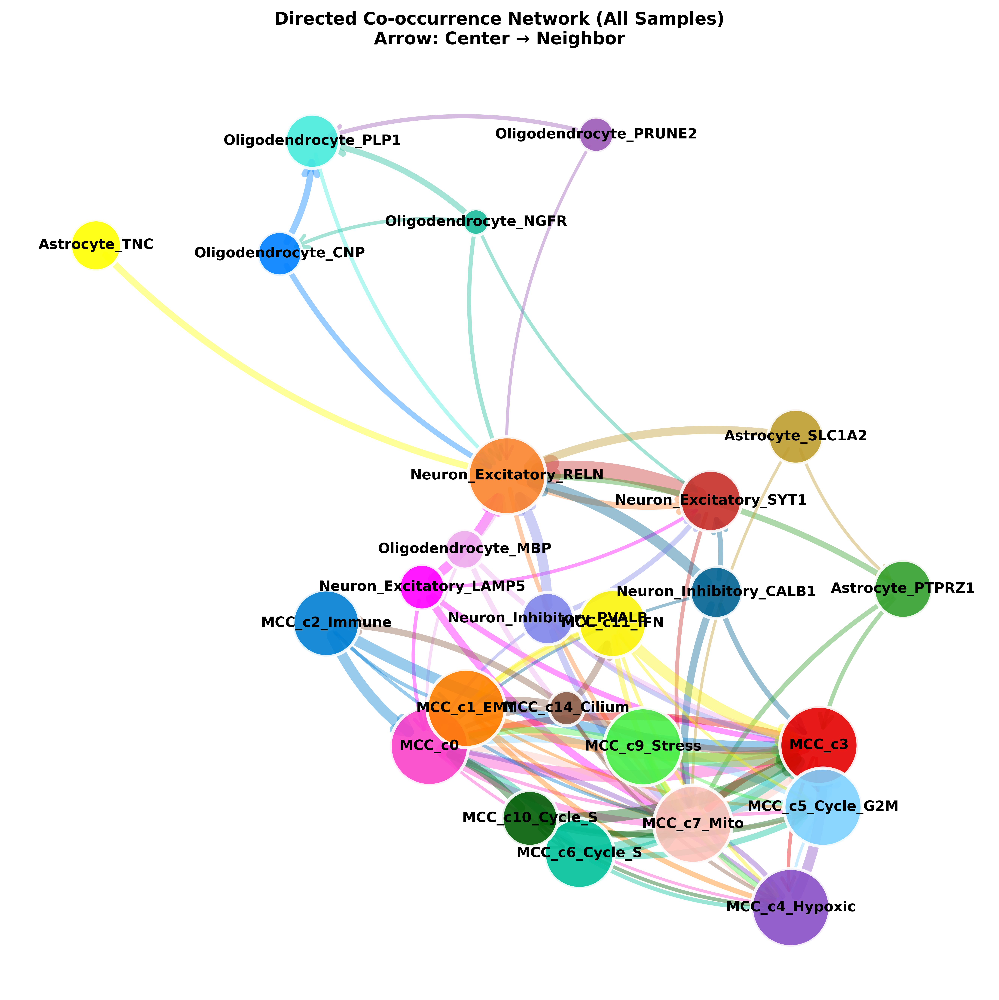

In [ ]:
# A → B 表示：B 经常出现在 A 的周围, A 被 B 包围
# 为了更清晰 ，只画部分细胞类型

# ------------------
# 定向共现 网络图（Directed Co-occurrence Network with ARROWS）
# ------------------
import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math


# ------------------
# 图 4｜细胞类型 定向共现网络（带颜色+节点大小正比于细胞数量）
# ------------------
# 全体样本 定向共现网络 
print("正在绘制：全体样本 定向共现网络")

# 加载已经存好的数据
directed_dict = adata.uns["all_sample_directed_cooccurrence"]
cell_types = adata.obs["CellType"].cat.categories.dropna()
sample_to_type = adata.obs.groupby("sample")["Type"].first()
first_df = next(iter(directed_dict.values()))
# used_cell_types = first_df.index.tolist()
used_cell_types = ["Neuron_Excitatory_LAMP5", "Neuron_Excitatory_RELN", "Neuron_Excitatory_SYT1", "Neuron_Inhibitory_CALB1", "Neuron_Inhibitory_PVALB", "Astrocyte_PTPRZ1", "Astrocyte_SLC1A2", "Astrocyte_TNC", "Oligodendrocyte_CNP", "Oligodendrocyte_MBP", "Oligodendrocyte_NGFR", "Oligodendrocyte_PLP1", "Oligodendrocyte_PRUNE2", "MCC_c0", "MCC_c1_EMT", "MCC_c2_Immune", "MCC_c3", "MCC_c4_Hypoxic", "MCC_c5_Cycle_G2M", "MCC_c6_Cycle_S", "MCC_c7_Mito", "MCC_c9_Stress", "MCC_c11_IFN", "MCC_c10_Cycle_S", "MCC_c14_Cilium"]
# 计算细胞类型数量（用于节点大小）
sample_cell_counts = adata.obs["sample"].value_counts().to_dict()
# 计算细胞类型数量（用于节点大小）
cell_count = adata.obs['CellType'].value_counts().to_dict()  # 用你的sub/adata都行


# 计算方法三：【细胞级别加权】按细胞数量加权平均 
# 每个样本 × 每种细胞 的数量
sample_cell_count = adata.obs.groupby(['sample', 'CellType']).size().unstack(fill_value=0)
# 计算平均矩阵
n_ct = len(used_cell_types)
mean_all = np.zeros((n_ct, n_ct))
# 对每一种【中心细胞】单独加权平均
for i, ct_center in enumerate(used_cell_types):
	scores = []
	weights = [] 
	for sid, df in directed_dict.items():
		# 提取当前中心细胞 → 所有周围细胞的分数
		if ct_center in df.index:
			score_vec = df.loc[ct_center, used_cell_types].values
		else:
			score_vec = np.zeros(n_ct)   
		# 权重 = 该样本中【中心细胞】的数量（你要的！）
		w = sample_cell_count.loc[sid, ct_center] if ct_center in sample_cell_count.columns else 0
		if w > 0:
			scores.append(score_vec)
			weights.append(w)
	# 加权平均
	if len(scores) > 0:
		mean_all[i, :] = np.average(scores, axis=0, weights=weights)
mean_df = pd.DataFrame(mean_all, index=used_cell_types, columns=used_cell_types)


# 构建有向图
G = nx.DiGraph()
# threshold = np.percentile(mean_all[mean_all > 0], 0)  # 只保留前 100% 强连接
# threshold = np.percentile(mean_all[mean_all > 0], 30)  # 保留强连接
# threshold = np.percentile(mean_all[mean_all > 0], 50)  # 只保留前 50% 强连接
# threshold = 0.1
threshold = 0.05

for i, ct_center in enumerate(used_cell_types):
	for j, ct_neighbor in enumerate(used_cell_types):
		val = mean_all[i, j]
		if i != j and val > threshold:
			G.add_edge(ct_center, ct_neighbor, weight=val)
# 布局
pos = nx.spring_layout(G, k=1, iterations=500, threshold=1e-4, seed=1234)
# pos = nx.fruchterman_reingold_layout(G, k=3.5, iterations=500, threshold=1e-4, seed=1234)  # k=3.5, 节点之间的距离：越大越散开 # iterations=500, 迭代次数：越大布局越美观 # seed=42 固定随机，每次图一样（可复现）
# 颜色匹配 CellType
cell_type_list = list(G.nodes())
color_map = []
for ct in cell_type_list:
	idx = np.where(adata.obs['CellType'].cat.categories == ct)[0][0]
	color_map.append(adata.uns['CellType_colors'][idx])
# 节点大小（数量成比例）
# node_size = [cell_count.get(ct, 100) * 0.8 for ct in G.nodes()]
# node_size = [min(max(50, cell_count.get(ct, 1) * 0.15), 1800) for ct in G.nodes()] # 简单安全版
# 稳定版（对数缩放 + 封顶，绝不巨大、绝不遮盖）
min_size = 150    # 最小节点
max_size = 2500   # 最大节点（不超标）
node_size = []
for ct in G.nodes():
	cnt = cell_count.get(ct, 1)
	# 平方根：比 log 区分度更大，但依然可控
	size = min_size + math.sqrt(cnt) * 8  
	size = min(size, max_size)  # 绝不超过上限
	node_size.append(size)

# 绘图（带箭头）
plt.figure(figsize=(9,9))
nx.draw_networkx_nodes(G, pos, node_color=color_map, node_size=node_size, alpha=0.9, edgecolors="white", linewidths=2)
# 箭头颜色 = 发出箭头的节点颜色
edge_colors = []
for u, v, d in G.edges(data=True):
    idx = list(G.nodes()).index(u)
    edge_colors.append(color_map[idx])
# 连线粗细 = 互作强度
nx.draw_networkx_edges(G, pos, width=[d["weight"]*35 for u,v,d in G.edges(data=True)], alpha=0.4, edge_color=edge_colors, arrowstyle="->", arrowsize=20, connectionstyle="arc3,rad=0.15")
# 标签
nx.draw_networkx_labels(G, pos, font_size=9, font_weight="bold")
plt.grid(False)
plt.axis("off")
plt.title("Directed Co-occurrence Network (All Samples)\nArrow: Center → Neighbor", fontweight="bold")
plt.tight_layout()
save_fig("cell_directed_cooccurrence_network_all.MCC_Nerve.threshold.0.05", fig_dir)
# plt.close()



【Step 13】 Tumor Core and  Boundary (固定半径邻域 200 + 50% 阈值划分 + 3圈空间标签平滑降噪)
-

In [ ]:

# ==============================================================================
# METHODS: 13. Tumor Core and  Boundary
# Detailed Description: Spatial cellular architecture was comprehensively profiled 
# using Squidpy spatial analysis tools to map cell type distributions across 
# histological sections. Cell-type co-occurrence analysis was performed to identify 
# non-random spatial associations between cellular populations. Neighborhood 
# enrichment statistics were computed to quantify significant spatial interactions, 
# while multi-parameter overlay plots integrated transcriptomic, phenotypic, and 
# spatial data at single-cell resolution to delineate the structural organization 
# of the metastatic brain tumor microenvironment.
# ==============================================================================
print("\n【Step 13】 Tumor Core and  Boundary")
fig_dir = os.path.join(out_dir, "Step13_Region", "Radius_200_36")
csv_dir = os.path.join(out_dir, "Step13_Region", "Radius_200_36")
os.makedirs(fig_dir, exist_ok=True)
os.makedirs(csv_dir, exist_ok=True)



【Step 13】 Tumor Core and  Boundary


In [ ]:

# 固定所有随机种子
seed = 1234
random.seed(seed)
np.random.seed(seed)
sc.settings.seed = seed


In [ ]:
for sid in sample_list:
	sub = adata[adata.obs["sample"] == sid].copy()
	# 过滤CellType为空的细胞
	sub = sub[~sub.obs["CellType"].isna()].copy()

	# 样本细胞过少或无恶性细胞则跳过
	if sub.n_obs < 10 or "Malignant_Cell" not in sub.obs["tumor_status"].unique():
		continue

	# 可视化分区结果
	sq.pl.spatial_scatter(sub, color="tumor_region", size=1, img=False, frameon=False, legend_fontsize=4, figsize=(8, 8), shape=None)
	save_fig(f"tumor_core_boundary_smooth_radius{RADIUS}_{sid}", fig_dir)
	plt.close()


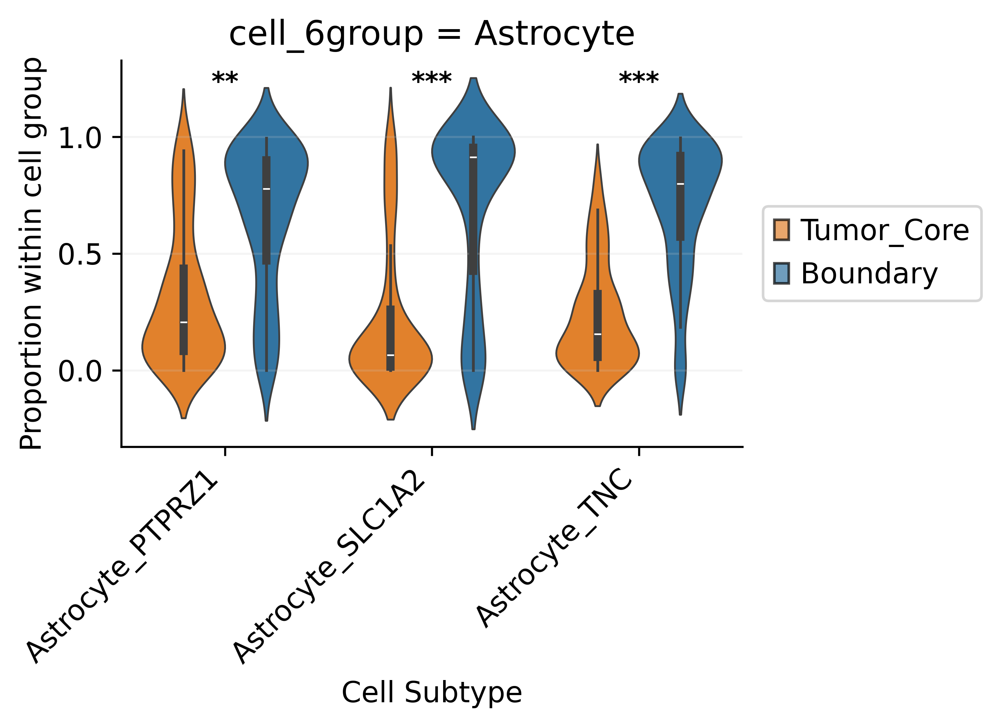

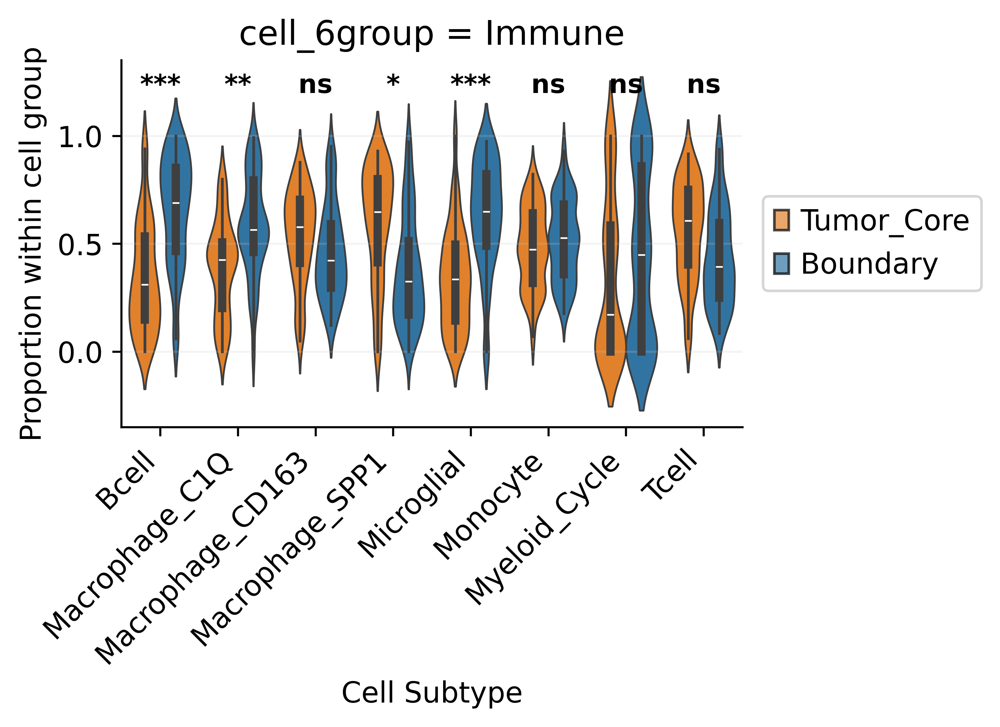

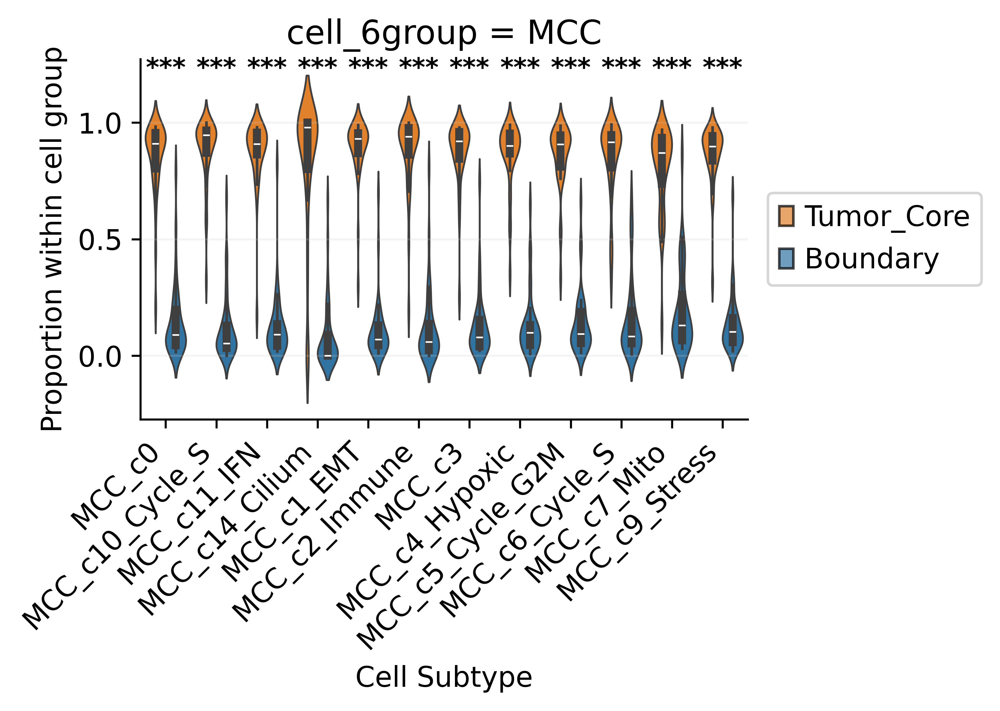

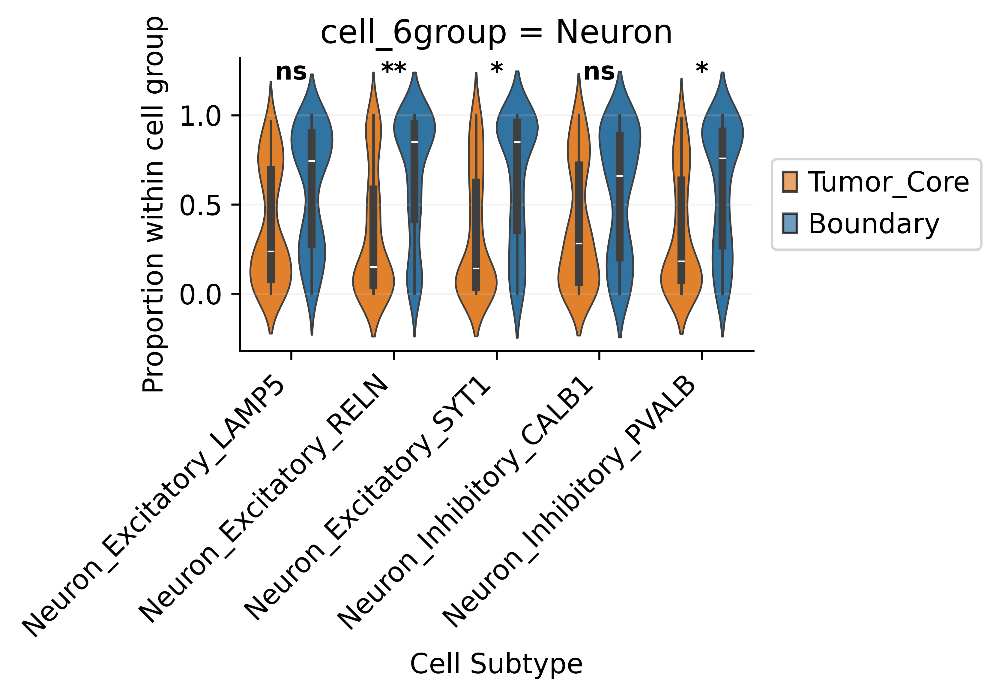

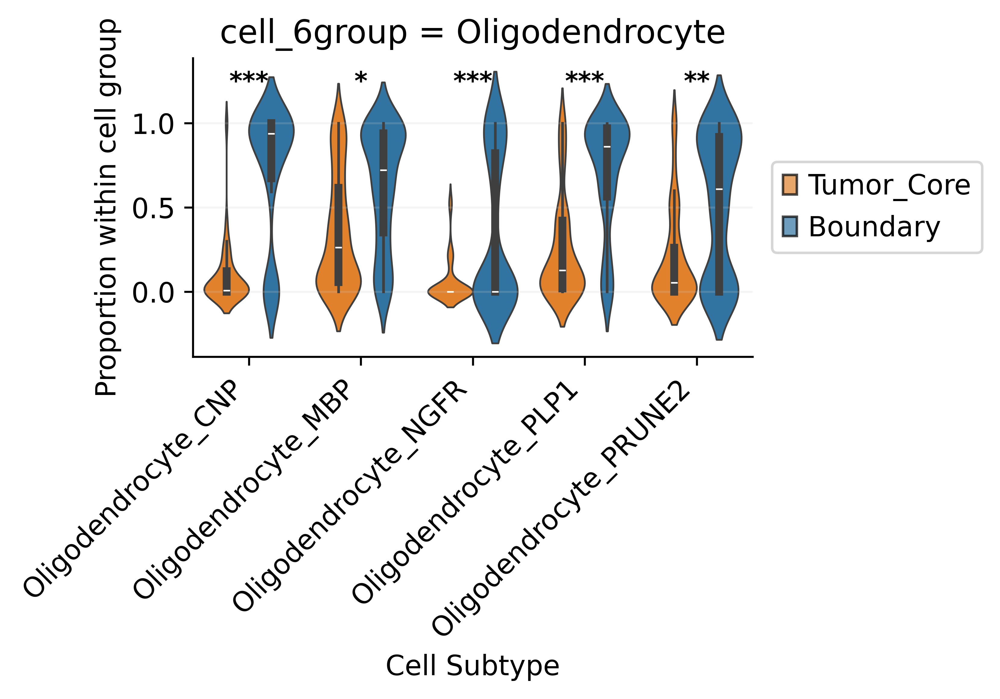

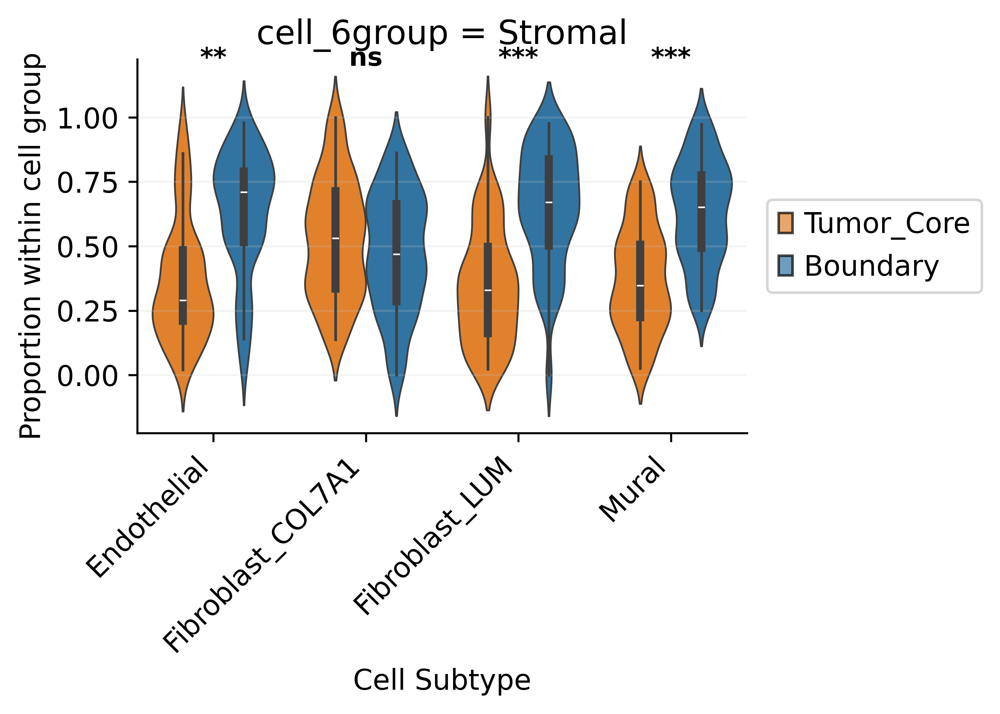

In [ ]:
# 按细胞大类分面绘图
# 比较每样本中， 每种 CellType 在  Tumor_Core 和 Boundary 中的比例

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy import stats

# 显著性函数
def get_significance_star(p):
	if p < 0.001:
		return "***"
	elif p < 0.01:
		return "**"
	elif p < 0.05:
		return "*"
	else:
		return "ns"

# 1. 原始数据读取，剔除cell_6group空值
df_raw_all = adata.obs[["sample", "CellType", "cell_6group", "tumor_region_Radius200_36"]].copy()
df_raw_all = df_raw_all.dropna(subset=["cell_6group"])

plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
# 遍历每一个细胞大类
group_list = sorted(df_raw_all["cell_6group"].astype(str).unique())
for target_group in group_list:
	# 只保留当前大类的原始数据
	df_raw = df_raw_all[df_raw_all["cell_6group"].astype(str) == target_group].copy()
	# 统计当前分组下：样本-细胞亚型-区域 细胞数量
	count_df = df_raw.groupby(["sample", "CellType", "tumor_region_Radius200_36"]).size().reset_index(name="cell_count")
	# 计算每个样本+细胞亚型下总细胞数
	total_per_sample_ct = count_df.groupby(["sample", "CellType"])["cell_count"].sum().reset_index(name="total_ct")
	count_df = count_df.merge(total_per_sample_ct, on=["sample", "CellType"])
	count_df["proportion"] = count_df["cell_count"] / count_df["total_ct"]
	# 只对当前分组内存在的CellType做组合补齐
	exist_cts = sorted(df_raw["CellType"].unique())  # 排序固定X轴顺序
	all_comb = pd.MultiIndex.from_product(
		[
			df_raw["sample"].unique(),
			exist_cts,
			["Tumor_Core", "Boundary"]
		],
		names=["sample", "CellType", "tumor_region_Radius200_36"]
	).to_frame(index=False)
	
	df_plot = all_comb.merge(
		count_df[["sample", "CellType", "tumor_region_Radius200_36", "proportion"]],
		how="left",
		on=["sample", "CellType", "tumor_region_Radius200_36"]
	).fillna({"proportion": 0})

	if df_plot.empty:
		print(f"分组 {target_group} 无有效数据，跳过")
		continue

	# key必须和分组字符串完全一致，自己改hex色号即可
	region_color_map = {
		"Tumor_Core": "#ff7f0e",   # 肿瘤核心：seaborn 默认第二组橙黄色
		"Boundary": "#1f77b4"      # 边界：seaborn 默认第一组蓝色
	}
	# 自适应画布宽度
	fig_width = max(6, len(exist_cts) * 0.4)
	plt.figure(figsize=(fig_width, 4))
	ax = sns.violinplot(data=df_plot, x="CellType", y="proportion", hue="tumor_region_Radius200_36", inner="box", scale="width", linewidth=0.7, dodge=True, bw_adjust=0.7, order=exist_cts, palette=region_color_map)
	# 白色中空箱线
	for patch in ax.findobj(lambda x: isinstance(x, plt.Rectangle)):
		patch.set_facecolor("white")
		patch.set_edgecolor("black")
	# ax.set_ylim(bottom=0)
	plt.xticks(rotation=45, ha="right")
	ax.set_xlabel("Cell Subtype", fontsize=11)
	ax.set_ylabel("Proportion within cell group", fontsize=11)
	ax.set_title(f"cell_6group = {target_group}", fontsize=13)
	ax.grid(axis="y", alpha=0.2)
	# 带填充色右侧图例
	if len(ax.collections) >= 2:
		core_color = ax.collections[0].get_facecolor()[0]
		bound_color = ax.collections[1].get_facecolor()[0]
		legend_elements = [
			Patch(facecolor=core_color, edgecolor="black", alpha=0.7, label="Tumor_Core"),
			Patch(facecolor=bound_color, edgecolor="black", alpha=0.7, label="Boundary")
		]
		ax.legend(handles=legend_elements, loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=True, fontsize=11)
	# 按指定的exist_cts顺序做统计检验，和X轴严格对齐
	p_list = []
	for ct in exist_cts:
		core_vals = df_plot[(df_plot["CellType"] == ct) & (df_plot["tumor_region_Radius200_36"] == "Tumor_Core")]["proportion"].values
		bound_vals = df_plot[(df_plot["CellType"] == ct) & (df_plot["tumor_region_Radius200_36"] == "Boundary")]["proportion"].values
		_, p = stats.ttest_rel(core_vals, bound_vals)
		p_list.append(p)
	# 标注显著性
	y_max = df_plot["proportion"].max() * 1.2
	for idx, ct in enumerate(exist_cts):
		star = get_significance_star(p_list[idx])
		ax.text(idx, y_max, star, ha="center", fontsize=10, fontweight="bold")
	plt.tight_layout(rect=[0, 0, 0.92, 1])
	# 保存每张分组独立图片
	save_fig(f"CellType.proportion.core_vs_boundary.violin.cell_6group.facet.{target_group}", fig_dir)
	# plt.close()
